# Credit Scoring v2 – impostazione orientata al rischio
Il notebook v1 (`credit_scoring_project.ipynb`) risolve una classificazione spiegabile.
Il v2 lo porta verso pratiche di settore:
- split train / validation / test: modelli e soglia scelti su validation, test usato una sola volta;
- imputazione calcolata solo sul train (nel v1 la mediana di DAYS_EMPLOYED usava tutto il dataset);
- metriche di rischio (Gini, KS) oltre a precision/recall;
- modello logistico con WoE e scorecard a punti;
- soglia scelta con un criterio di costo dichiarato.
Limite noto: il dataset è probabilmente sintetico e la classe 1 (affidabile) è solo l'8,8%,
quindi le metriche non sono rappresentative di un portafoglio reale e non si calibra una PD.

## Import

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from lightgbm import LGBMClassifier

SEED = 42
SEED_SPLIT = 43
URL = "https://proai-datasets.s3.eu-west-3.amazonaws.com/credit_scoring.csv"

## Cleaning and Data preprocessing

In [2]:
df = pd.read_csv(URL)

Cleaning from the v1 EDA

In [3]:
df = df.drop(columns=["ID", "FLAG_MOBIL"])
df = df.dropna(subset=["DAYS_BIRTH"])            # only incomplete record incompleto (like in v1)
print(df.shape, df["TARGET"].value_counts(normalize=True).round(3).to_dict())

(338426, 17) {0: 0.912, 1: 0.088}


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 338426 entries, 0 to 338425
Data columns (total 17 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   CODE_GENDER          338426 non-null  object 
 1   FLAG_OWN_CAR         338426 non-null  object 
 2   FLAG_OWN_REALTY      338426 non-null  object 
 3   CNT_CHILDREN         338426 non-null  int64  
 4   AMT_INCOME_TOTAL     338426 non-null  float64
 5   NAME_INCOME_TYPE     338426 non-null  object 
 6   NAME_EDUCATION_TYPE  338426 non-null  object 
 7   NAME_FAMILY_STATUS   338426 non-null  object 
 8   NAME_HOUSING_TYPE    338426 non-null  object 
 9   DAYS_BIRTH           338426 non-null  float64
 10  DAYS_EMPLOYED        338426 non-null  float64
 11  FLAG_WORK_PHONE      338426 non-null  float64
 12  FLAG_PHONE           338426 non-null  float64
 13  FLAG_EMAIL           338426 non-null  float64
 14  OCCUPATION_TYPE      235085 non-null  object 
 15  CNT_FAM_MEMBERS      3

### Dataset split

In [5]:
X = df.drop(columns="TARGET")
y = df["TARGET"]          # 1 = affidabile; "bad" = 0 (convenzione per WoE e KS)

X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED_SPLIT)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=SEED_SPLIT)

In [6]:
dict_partitions = {"Train":X_train, "Validation":X_val, "Test":X_test}
total_len = df.shape[0]
for name, partition in dict_partitions.items():
    print(f"{name}:\t Size {partition.shape[0]},\t Percentage: {round(partition.shape[0]*100/total_len, 2)} %")

Train:	 Size 203055,	 Percentage: 60.0 %
Validation:	 Size 67685,	 Percentage: 20.0 %
Test:	 Size 67686,	 Percentage: 20.0 %


### Preprocessing & Pipeline

In [7]:
from sklearn.preprocessing import FunctionTransformer
from sklearn.impute import SimpleImputer

def add_flags(X, keep_flag=False):
    """Valori anomali di DAYS_EMPLOYED a NaN; il flag è opzionale (nel modello non si usa)."""
    X = X.copy()
    if keep_flag:
        X["DAYS_EMPLOYED_ANOM"] = (X["DAYS_EMPLOYED"] > 0).astype(int)
    X["DAYS_EMPLOYED"] = X["DAYS_EMPLOYED"].where(X["DAYS_EMPLOYED"] <= 0, np.nan)
    return X

Xf = add_flags(X_train)
text_cols = list(Xf.select_dtypes("object").columns)
bin_cols  = [c for c in Xf.columns if c not in text_cols and set(Xf[c].dropna().unique()) <= {0, 1}]
num_cols  = [c for c in Xf.columns if c not in text_cols + bin_cols]

def make_preprocessor(scale):
    num_steps = [("imp", SimpleImputer(strategy="median"))]    # mediana appresa solo sul train
    if scale:
        num_steps.append(("sc", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_cols),
        ("txt", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Missing")),
                          ("oh", OneHotEncoder(drop="first", handle_unknown="ignore"))]), text_cols),
        ("bin", "passthrough", bin_cols),
    ])

## Preliminar analysis on Train set

In [8]:
eda = add_flags(X_train, True)
eda["TARGET"] = y_train
eda["AGE_YEARS"] = -eda["DAYS_BIRTH"] / 365.25
# anni di lavoro solo dove il dato è reale (le anomalie positive erano state imputate)
eda["YEARS_EMPLOYED"] = -eda["DAYS_EMPLOYED"] / 365.25
eda['OCCUPATION_TYPE'] = eda['OCCUPATION_TYPE'].fillna("Missing")

In [9]:
# +1 = valori più alti attesi negli affidabili; -1 = più bassi
expected = {
    "AMT_INCOME_TOTAL": +1,
    "AGE_YEARS": +1,
    "YEARS_EMPLOYED": +1,
    "CNT_CHILDREN": -1,
    "CNT_FAM_MEMBERS": -1,
}
rows = []
for var, sign in expected.items():
    d = eda[[var, "TARGET"]].dropna()
    good, bad = d.loc[d.TARGET == 1, var], d.loc[d.TARGET == 0, var]
    auc = roc_auc_score(d.TARGET, d[var])            # >0.5: valori alti -> affidabile
    delta = auc - 0.5
    if abs(delta) < 0.02:
        verdict = "debole"
    else:
        verdict = "coerente" if np.sign(delta) == sign else "incoerente"
    rows.append({"variabile": var, "attesa": "+" if sign > 0 else "-",
                 "mediana affidabili": good.median(), "mediana non affidabili": bad.median(),
                 "Q1-Q3 affidabili": f"{good.quantile(.25):.1f}-{good.quantile(.75):.1f}",
                 "Q1-Q3 non affidabili": f"{bad.quantile(.25):.1f}-{bad.quantile(.75):.1f}",
                 "AUC univariata": round(auc, 3), "esito": verdict})
pd.DataFrame(rows)

,variabile,attesa,mediana affidabili,mediana non affidabili,Q1-Q3 affidabili,Q1-Q3 non affidabili,AUC univariata,esito
0,AMT_INCOME_TOTAL,+,228787.815000,157724.970000,198807.7-301166.9,115122.7-220210.6,0.792,coerente
1,AGE_YEARS,+,50.006845,41.270363,46.1-54.3,33.4-53.1,0.705,coerente
2,YEARS_EMPLOYED,+,10.272416,4.720055,6.8-16.2,2.3-8.8,0.777,coerente
3,CNT_CHILDREN,-,0.000000,0.000000,0.0-0.0,0.0-1.0,0.420,coerente
4,CNT_FAM_MEMBERS,-,2.000000,2.000000,2.0-2.0,2.0-3.0,0.431,coerente


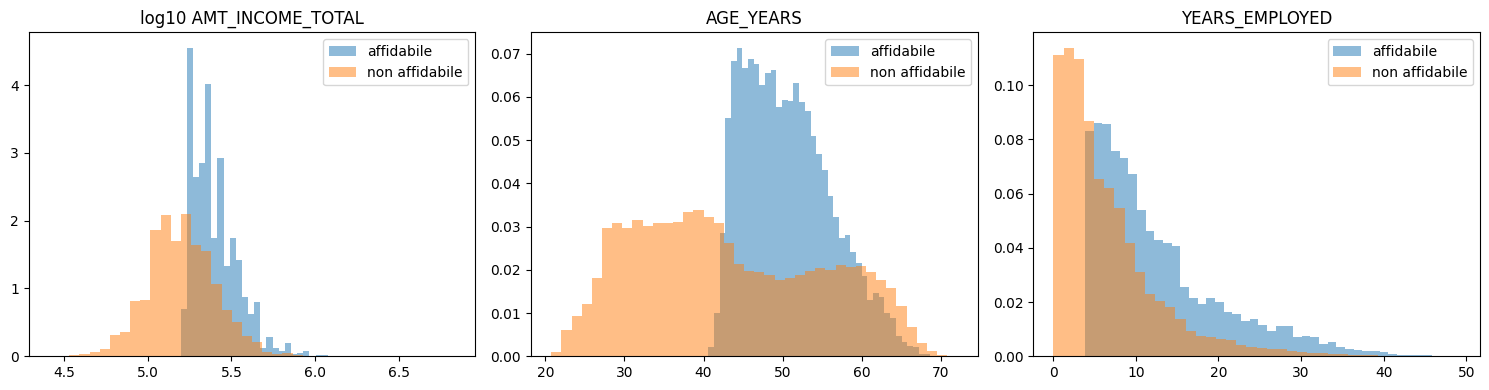

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, var, log in zip(axes, ["AMT_INCOME_TOTAL", "AGE_YEARS", "YEARS_EMPLOYED"], [True, False, False]):
    for t, lab in [(1, "affidabile"), (0, "non affidabile")]:
        v = eda.loc[eda.TARGET == t, var].dropna()
        ax.hist(np.log10(v) if log else v, bins=40, density=True, alpha=0.5, label=lab)
    ax.set_title(("log10 " if log else "") + var); ax.legend()
plt.tight_layout(); plt.show()

In [11]:
base = eda["TARGET"].mean()
for col in ["NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "NAME_HOUSING_TYPE",
            "NAME_FAMILY_STATUS", "OCCUPATION_TYPE", "FLAG_OWN_REALTY", "FLAG_OWN_CAR"]:
    t = eda.groupby(col)["TARGET"].agg(n="size", tasso="mean")
    t["lift"] = t["tasso"] / base                      # >1: più affidabili della media
    t["campione piccolo"] = t["n"] < 500
    print(f"\n{col} (media complessiva del Train Target {base:.3f})")
    display(t.sort_values("tasso", ascending=False).round(3))


NAME_INCOME_TYPE (media complessiva del Train Target 0.088)


,n,tasso,lift,campione piccolo
NAME_INCOME_TYPE,,,,
Student,8,0.250,2.846,True
State servant,16918,0.134,1.523,False
Commercial associate,46787,0.120,1.364,False
Working,104678,0.095,1.084,False
Pensioner,34664,0.000,0.000,False



NAME_EDUCATION_TYPE (media complessiva del Train Target 0.088)


,n,tasso,lift,campione piccolo
NAME_EDUCATION_TYPE,,,,
Academic degree,139,0.151,1.720,True
Higher education,54958,0.103,1.178,False
Secondary / secondary special,139316,0.084,0.953,False
Incomplete higher,6771,0.058,0.657,False
Lower secondary,1871,0.040,0.450,False



NAME_HOUSING_TYPE (media complessiva del Train Target 0.088)


,n,tasso,lift,campione piccolo
NAME_HOUSING_TYPE,,,,
Municipal apartment,6491,0.109,1.240,False
Office apartment,1742,0.094,1.072,False
House / apartment,182721,0.091,1.034,False
Co-op apartment,707,0.068,0.773,False
Rented apartment,2655,0.050,0.566,False
With parents,8739,0.022,0.251,False


... (4 outputs left out)


FLAG_OWN_REALTY (media complessiva del Train Target 0.088)


,n,tasso,lift,campione piccolo
FLAG_OWN_REALTY,,,,
Y,138647,0.093,1.063,False
N,64408,0.076,0.864,False



FLAG_OWN_CAR (media complessiva del Train Target 0.088)


,n,tasso,lift,campione piccolo
FLAG_OWN_CAR,,,,
Y,75217,0.101,1.154,False
N,127838,0.080,0.910,False


### Variabili categoriche vs Target 

- **`NAME_INCOME_TYPE`**: coerente per State servant (1,52), Commercial associate (1,36) e Working (1,08). **Pensioner ha tasso 0,000 su 34.664 record**, cioè nessun affidabile: è un'anomalia (vedi sotto). Student (n=8) ignorato.
- **`NAME_EDUCATION_TYPE`**: ordine quasi monotono (Higher 0,103 → Secondary 0,084 → Lower secondary 0,040), con un'inversione non spiegata: Incomplete higher (0,058) è sotto Secondary. Academic degree è coerente ma piccolo (n=139).
- **`NAME_HOUSING_TYPE`**: coerente, With parents (0,022) e Rented (0,050) sono i più bassi, mentre House/Municipal/Office stanno sopra la media; Co-op (0,068) è intermedio.
- **`NAME_FAMILY_STATUS`**: effetto debole (lift 0,83-1,37); Separated e Widow sopra, Single sotto. Non avevamo un'attesa forte, ma Separated al top non è intuitivo e potrebbe riflettere l'età.
- **`OCCUPATION_TYPE`**: coerente in alto (Managers 1,03, Medicine, Accountants, High skill) e in basso (Waiters 0,024, Low-skill, Sales); Drivers e Laborers sopra la media sono poco intuitivi. HR staff, Realty agents e IT staff sono piccoli e non interpretabili.
- **`Missing` in `OCCUPATION_TYPE`**: 62.123 record, tasso 0,044 (lift 0,50). Probabilmente è in gran parte lo stesso gruppo dei pensionati; da verificare.
- **`FLAG_OWN_REALTY`**: coerente ma debole (0,093 contro 0,076).
- **`FLAG_OWN_CAR`**: coerente ma debole (0,101 contro 0,080).

In [12]:
display(pd.crosstab(eda["NAME_INCOME_TYPE"] == "Pensioner", eda["DAYS_EMPLOYED_ANOM"]))
display(pd.crosstab(eda["NAME_INCOME_TYPE"] == "Pensioner", eda["OCCUPATION_TYPE"] == "Missing"))
print("Tasso senza pensionati: ", eda.loc[eda["NAME_INCOME_TYPE"] != "Pensioner", "TARGET"].mean().round(3))   # tasso senza pensionati

DAYS_EMPLOYED_ANOM,0,1
NAME_INCOME_TYPE,,
False,168391,0
True,0,34664


OCCUPATION_TYPE,False,True
NAME_INCOME_TYPE,,
False,140932,27459
True,0,34664


Tasso senza pensionati:  0.106


In [13]:
mask_missing = eda["OCCUPATION_TYPE"] == "Missing"
mask_pens = eda["NAME_INCOME_TYPE"] == "Pensioner"
print("Missing non pensionati:", (mask_missing & ~mask_pens).sum(),
      " tasso:", round(eda.loc[mask_missing & ~mask_pens, "TARGET"].mean(), 3))

Missing non pensionati: 27459  tasso: 0.099


### Pensionati

**Cosa emerge**
- Tutti i 34.664 pensionati (17% del train) hanno `TARGET = 0`: il tasso di affidabili è 0,000 contro 0,088 complessivo. Non è una tendenza ma una regola deterministica.
- I pensionati coincidono al 100% con `DAYS_EMPLOYED_ANOM = 1` (valori positivi di `DAYS_EMPLOYED`) e con `OCCUPATION_TYPE = Missing`. Le tre informazioni descrivono lo stesso segmento.
- Escludendo i pensionati il tasso di affidabili sale da 0,088 a 0,106. È un effetto aritmetico (si toglie un gruppo a tasso zero) e non un'evidenza sul comportamento dei pensionati.
- La modalità "Missing" di `OCCUPATION_TYPE` appare rischiosa (0,044 su 62.123 record) solo perché contiene tutti i pensionati: i 27.459 "Missing" non pensionati hanno un tasso di 0,099, in linea con la media dei non pensionati (0,106). "Missing" non è quindi un segnale di rischio in sé.

**Interpretazione**
- Nella realtà i pensionati non sono mai tutti non affidabili. La definizione del target ("1 = paga le rate con regolarità") non spiega un 100%, quindi lo trattiamo come artefatto di costruzione del dataset, in linea con l'ipotesi che sia sintetico o molto preprocessato.
- Il segmento può gonfiare le metriche di discriminazione (AUC, Gini, KS): un sesto dei record è classificabile da una sola regola, senza alcuna informazione di rischio.

**Limite:** non possiamo sapere se la regola derivi dalla definizione dell'etichetta o dalla generazione dei dati; non si interpreta come causa economica.

**Scelta:** `DAYS_EMPLOYED_ANOM` viene tolta dalle feature: è ridondante con la modalità "Pensioner". 


## Validation metrics

In [14]:
# keep_flag=False esplicito come da scelta dell'analisi prcedente
lr  = Pipeline([("flags", FunctionTransformer(add_flags, kw_args={"keep_flag": False})), ("preprocessor", make_preprocessor(True)),
                ("model", LogisticRegression(solver="liblinear", random_state=SEED))]).fit(X_train, y_train)
gbm = Pipeline([("flags", FunctionTransformer(add_flags, kw_args={"keep_flag": False})), ("preprocessor", make_preprocessor(False)),
                ("model", LGBMClassifier(random_state=SEED, verbose=-1))]).fit(X_train, y_train)

In [15]:
def gini(y_true, score):
    return 2 * roc_auc_score(y_true, score) - 1

def ks_stat(y_true, score):
    fpr, tpr, _ = roc_curve(y_true, score)
    return float(np.max(tpr - fpr))

def risk_report(name, y_true, score):
    return {"modello": name, "AUC": roc_auc_score(y_true, score),
            "Gini": gini(y_true, score), "KS": ks_stat(y_true, score)}

In [16]:
mask_pens_val = X_val["NAME_INCOME_TYPE"] == "Pensioner"
print(f"Pensionati in validation: {mask_pens_val.sum()} ({mask_pens_val.mean():.1%})")

Pensionati in validation: 11490 (17.0%)


In [17]:
scores = {"Logistica (v1-like)": lr.predict_proba(X_val)[:, 1],
          "LightGBM base": gbm.predict_proba(X_val)[:, 1]}

c:\Users\Tia\Desktop\ProfessionAI\Progetti\data-science-portfolio\[Data Science] credit_scoring_prediction\credit_scoring_venv\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [18]:
rows = []
for name, s in scores.items():
    s = pd.Series(s, index=X_val.index)
    for label, m in [("tutti", slice(None)), ("senza pensionati", ~mask_pens_val)]:
        yy, ss = y_val[m], s[m]
        rows.append({"modello": name, "popolazione": label, "n": len(yy),
                     "tasso affidabili": round(yy.mean(), 3),
                     "AUC": roc_auc_score(yy, ss), "Gini": gini(yy, ss), "KS": ks_stat(yy, ss)})
pd.DataFrame(rows).round(3)

,modello,popolazione,n,tasso affidabili,AUC,Gini,KS
0,Logistica (v1-like),tutti,67685,0.088,0.916,0.832,0.713
1,Logistica (v1-like),senza pensionati,56195,0.106,0.897,0.794,0.665
2,LightGBM base,tutti,67685,0.088,0.979,0.957,0.939
3,LightGBM base,senza pensionati,56195,0.106,0.974,0.948,0.927


In [ ]:
from sklearn.tree import DecisionTreeClassifier
for d in [2, 3, 5]:
    t = Pipeline([("flags", FunctionTransformer(add_flags)), ("prep", make_preprocessor(False)),
                  ("m", DecisionTreeClassifier(max_depth=d, random_state=SEED))]).fit(X_train, y_train)
    print(f"Decision Tree with max depth: {d}, Gini: {round(gini(y_val, t.predict_proba(X_val)[:, 1]), 3)}")

Decision Tree with max depth: 2, 0.82
Decision Tree with max depth: 3, 0.931
Decision Tree with max depth: 5, 0.956


In [20]:
t3 = Pipeline([("flags", FunctionTransformer(add_flags)), ("prep", make_preprocessor(False)),
               ("m", DecisionTreeClassifier(max_depth=3, random_state=SEED))]).fit(X_train, y_train)
from sklearn.tree import export_text
names = list(t3.named_steps["prep"].get_feature_names_out())
print(export_text(t3.named_steps["m"], feature_names=names))

|--- num__AMT_INCOME_TOTAL <= 164805.88
|   |--- num__AMT_INCOME_TOTAL <= 162662.41
|   |   |--- num__AMT_INCOME_TOTAL <= 159945.45
|   |   |   |--- class: 0
|   |   |--- num__AMT_INCOME_TOTAL >  159945.45
|   |   |   |--- class: 0
|   |--- num__AMT_INCOME_TOTAL >  162662.41
|   |   |--- num__DAYS_EMPLOYED <= -4959.50
|   |   |   |--- class: 0
|   |   |--- num__DAYS_EMPLOYED >  -4959.50
|   |   |   |--- class: 0
|--- num__AMT_INCOME_TOTAL >  164805.88
|   |--- num__DAYS_BIRTH <= -15545.50
|   |   |--- num__DAYS_EMPLOYED <= -1944.50
|   |   |   |--- class: 1
|   |   |--- num__DAYS_EMPLOYED >  -1944.50
|   |   |   |--- class: 0
|   |--- num__DAYS_BIRTH >  -15545.50
|   |   |--- num__DAYS_BIRTH <= -15201.50
|   |   |   |--- class: 0
|   |   |--- num__DAYS_BIRTH >  -15201.50
|   |   |   |--- class: 0



Predizione di affidabile (classe 1) se:
- reddito > ~165.000 e 
- età > ~42,6 anni (DAYS_BIRTH ≤ −15.545) e 
- anzianità lavorativa > ~5,3 anni (DAYS_EMPLOYED ≤ −1.944)

Tutti gli altri rami sono classe 0. Le soglie intorno a 160-165 mila sul reddito nel ramo di sinistra (162.662, 159.945) sono il tentativo dell’albero di rifinire la stessa soglia: lette bene è una soglia sul reddito di circa 165 mila.

Conseguenze:
- L’etichetta sembra costruita da una regola con tre condizioni in AND. Questo spiega Gini 0,93 a profondità 3 e KS 0,93 del LightGBM: i modelli stanno ricostruendo la regola.
- Spiega i pensionati. Per loro DAYS_EMPLOYED è anomalo (diventa NaN), quindi non possono soddisfare “anzianità > 5,3 anni”: zero affidabili per costruzione. Coerente con l’ipotesi che l’etichetta richieda una storia lavorativa; resta un’ipotesi, perché dall’albero non si vede la regola originale.

### Metriche di partenza (validation)

Le metriche di Gini e KS sono riportate sia su tutta la popolazione sia **escludendo i pensionati**, per misurare il potere discriminante delle altre variabili.


| Modello | Popolazione | Gini | KS |
|---|---|---|---|
| Logistica (v1-like) | tutti / senza pensionati | 0,832 / 0,794 | 0,713 / 0,665 |
| LightGBM base | tutti / senza pensionati | 0,957 / 0,948 | 0,939 / 0,927 |

- Escludere i pensionati riduce poco le metriche (−0,04 di Gini per la logistica, −0,01 per LightGBM): il segnale discriminante non dipende dal solo segmento deterministico.
- LightGBM supera la logistica di circa 0,15 di Gini: la logistica su variabili grezze non cattura interazioni e non linearità.
- I valori (Gini ~0,95, KS ~0,93) sono molto più alti di quelli di un portafoglio reale e sono coerenti con un dataset sintetico: non vanno letti come performance attese in produzione.
- I valori su validation coincidono con quelli del v1 sul test (AUC 0,979 e 0,918): il bias di selezione ereditato dal v1 è trascurabile.

Gini (= 2·AUC − 1) e KS misurano la capacità del punteggio di ordinare i clienti: 
- il Gini è la probabilità che un affidabile ottenga un punteggio più alto di un non affidabile meno la probabilità opposta; 
- il KS è la massima distanza tra le distribuzioni cumulate dei due gruppi. 

Sono simmetrici rispetto alla scelta della classe positiva: invertendo le classi e il segno del punteggio i valori non cambiano. Cambiano invece precision, recall, soglia e significato della probabilità.

## Binning

**Scelte conseguenti nel v2**
3. La scorecard è costruita sulla popolazione senza pensionati; i pensionati sono trattati come segmento a regola di esclusione (knock-out), come farebbe un processo di credito reale.

## Il punto da trattare prima del binning

**Pensioner = 0 affidabili su 34.664.** Non è una tendenza, è una regola deterministica. Il README segnala che `DAYS_EMPLOYED_ANOM` coincide con i pensionati, quindi probabilmente anche il flag ha tasso 0. Conseguenze:
- **Nella logistica**: la modalità è quasi perfettamente separabile. Con `liblinear` e regolarizzazione L2 il modello converge, ma il coefficiente è molto grande.
- **Nel WoE**: con zero "good" il WoE è infinito. Servono accorpamenti o una correzione, che `optbinning` gestisce con parametri come il minimo di casi per classe.
- **Nel commento**: è l'ennesimo segnale di dataset sintetico o costruito. In un portafoglio reale i pensionati con zero affidabili sono impensabili.
- Il motivo per cui il modello raggiunge Gini ~0,96 potrebbe in parte stare qui, insieme a "Missing" e a `DAYS_EMPLOYED_ANOM`: un terzo del dataset è già classificato senza alcuna informazione di rischio.